# EDA — Default of Credit Card Clients

O objetivo aqui não é catalogar o dataset. É responder três perguntas que
mudam o desenho do motor de decisão:

1. Quais sinais comportamentais separam bons de maus, e com que força?
2. A perda potencial está espalhada pela base ou concentrada em poucas contas?
3. A economia da carteira fecha sem política de crédito?

A terceira pergunta é a que define contra o que o resultado do modelo será
comparado no README.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data, features

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
AZUL, VERMELHO, CINZA = "#1f4e79", "#c0392b", "#7f8c8d"

df = data.load()
X, y, aux = features.build(df)
print(f"{len(df):,} contas | {X.shape[1]} features | inadimplencia {y.mean():.2%}".replace(",", "."))

30.000 contas | 24 features | inadimplencia 22.12%


## 1. O alvo

22,12% de inadimplência é altíssimo para cartão de crédito. Não é ruído do
dataset: são contas de um emissor de Taiwan em 2005, durante o estouro do
crédito rotativo local. Vale registrar porque contamina qualquer comparação
com benchmark de carteira saudável.

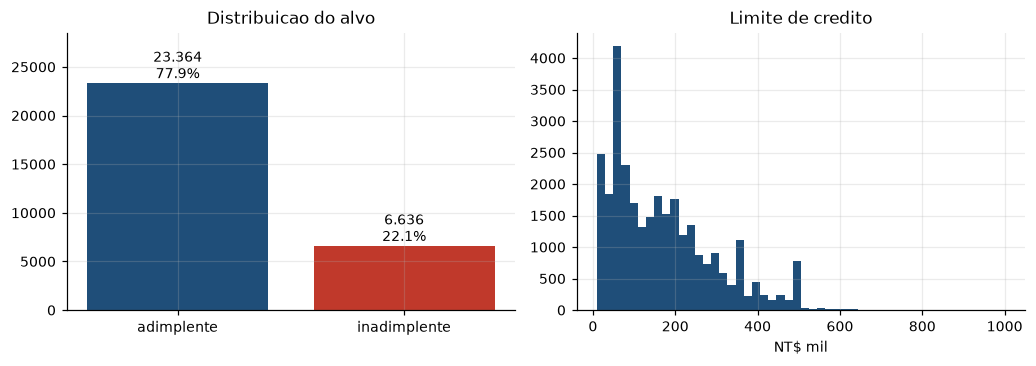

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))

vc = y.value_counts().sort_index()
axes[0].bar(["adimplente", "inadimplente"], vc.to_numpy(), color=[AZUL, VERMELHO])
for i, v in enumerate(vc):
    axes[0].text(i, v, f"{v:,}".replace(",", ".") + f"\n{v/len(y):.1%}", ha="center", va="bottom")
axes[0].set_title("Distribuicao do alvo"); axes[0].set_ylim(0, len(y) * 0.95)

axes[1].hist(df["limite_credito"] / 1000, bins=50, color=AZUL)
axes[1].set_title("Limite de credito"); axes[1].set_xlabel("NT$ mil")
plt.tight_layout(); plt.show()

## 2. Severidade de atraso

`status_atraso_m1` é o estado de pagamento no ciclo mais recente: −2 sem uso,
−1 pago integral, 0 rotativo, 1+ meses em atraso.

A relação é quase degrau. Quem está com 2 ciclos em atraso quebra em mais de
2 de cada 3 casos; quem pagou integral fica abaixo de 15%. É a feature mais
forte da base — e explica por que o modelo alcança KS de 0,42 sem nada exótico.

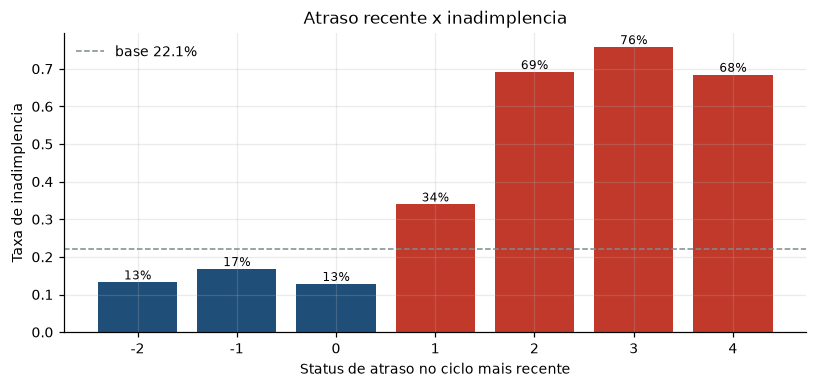

,atraso,contas,taxa
0,-2,2759,13.2%
1,-1,5686,16.8%
2,0,14737,12.8%
3,1,3688,33.9%
4,2,2667,69.1%
5,3,322,75.8%
6,4,76,68.4%


In [3]:
tab = (
    pd.DataFrame({"atraso": df["status_atraso_m1"], "y": y})
    .groupby("atraso").agg(contas=("y", "size"), taxa=("y", "mean")).reset_index()
)
tab = tab[tab["contas"] >= 50]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
cores = [VERMELHO if t > y.mean() else AZUL for t in tab["taxa"]]
ax.bar(tab["atraso"].astype(str), tab["taxa"], color=cores)
ax.axhline(y.mean(), color=CINZA, ls="--", lw=1, label=f"base {y.mean():.1%}")
for i, r in enumerate(tab.itertuples()):
    ax.text(i, r.taxa, f"{r.taxa:.0%}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("Status de atraso no ciclo mais recente")
ax.set_ylabel("Taxa de inadimplencia"); ax.set_title("Atraso recente x inadimplencia")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

display(tab.assign(taxa=lambda d: d["taxa"].map("{:.1%}".format)))

## 3. Utilização e pagamento

Duas features construídas, não originais do dataset. A taxa de pagamento é a
que exige cuidado: `pagamento_m{t}` quita a fatura de `fatura_m{t+1}`, e
dividir os dois pelo mesmo índice mede a coisa errada.

Quem quita integral a fatura tem risco baixo e estável. A degradação é forte
na faixa entre 0% e 20% de pagamento — pagar o mínimo é um sinal muito
diferente de não pagar nada.

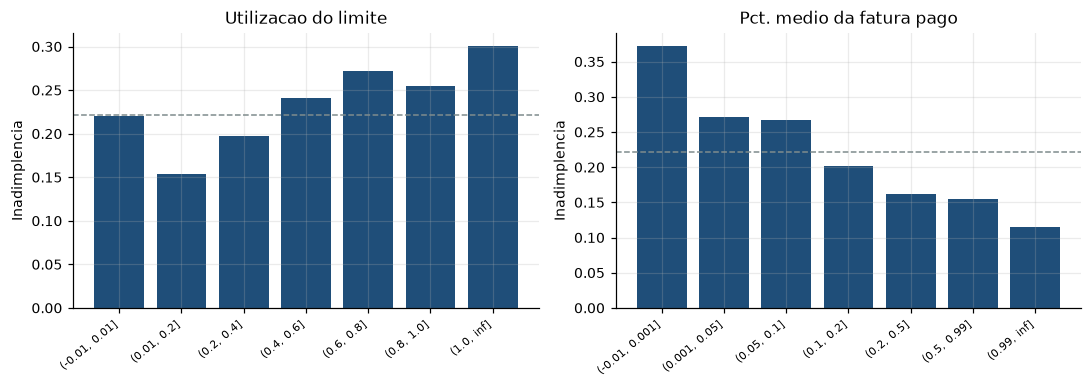

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

for ax, col, titulo, cortes in [
    (axes[0], "utilizacao_atual", "Utilizacao do limite",
     [-0.01, 0.01, 0.2, 0.4, 0.6, 0.8, 1.0, np.inf]),
    (axes[1], "taxa_pagamento_media_5m", "Pct. medio da fatura pago",
     [-0.01, 0.001, 0.05, 0.1, 0.2, 0.5, 0.99, np.inf]),
]:
    faixa = pd.cut(X[col], bins=cortes)
    t = pd.DataFrame({"f": faixa, "y": y}).groupby("f", observed=True)["y"].agg(["mean", "size"])
    t = t[t["size"] >= 100]
    ax.bar(range(len(t)), t["mean"], color=AZUL)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=40, ha="right", fontsize=7)
    ax.axhline(y.mean(), color=CINZA, ls="--", lw=1)
    ax.set_title(titulo); ax.set_ylabel("Inadimplencia")

plt.tight_layout(); plt.show()

## 4. Onde está o dinheiro em risco

Aqui a EDA deixa de ser descritiva e passa a informar a decisão.

Uma armadilha antes do gráfico: 77,88% das contas têm perda **zero por
construção**, porque não quebraram. Traçar uma curva de concentração da perda
sobre a base inteira produz um número impressionante e vazio — ele mede
sobretudo a taxa de default, não desigualdade de exposição.

As duas coisas precisam ser separadas: concentração da **exposição** entre
todas as contas, e concentração da **perda** entre quem de fato quebrou.

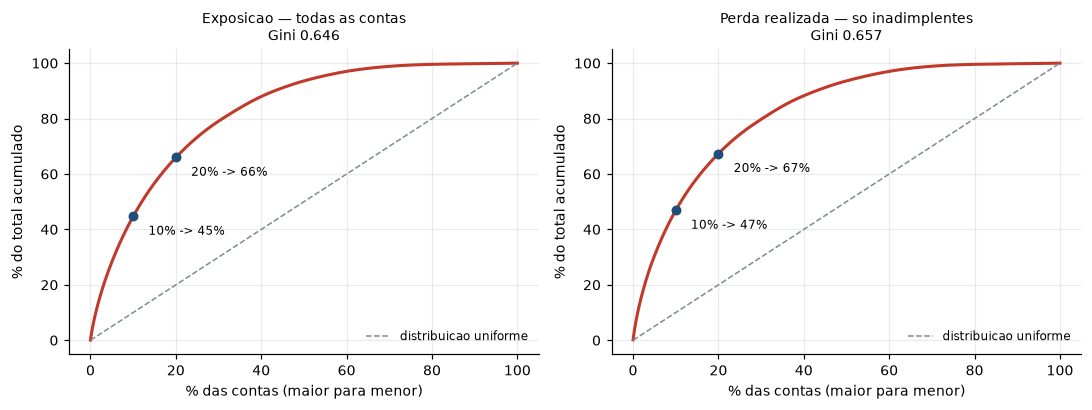

contas com perda > 0: 22.12% da base (por construcao)

  exposicao (base inteira)     Gini 0.646   10%->44.7% | 20%->66.0% | 50%->93.6%
  perda (so inadimplentes)     Gini 0.657   10%->46.9% | 20%->67.3% | 50%->93.6%


In [5]:
exp = aux["exposicao"].to_numpy()
y_np = y.to_numpy()


def lorenz(valores):
    v = np.sort(valores)[::-1]
    return np.arange(1, len(v) + 1) / len(v), np.cumsum(v) / v.sum()


def gini(valores):
    v = np.sort(valores)
    n = len(v)
    return float((2 * np.sum((np.arange(1, n + 1)) * v)) / (n * v.sum()) - (n + 1) / n)


fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

for ax, valores, titulo in [
    (axes[0], exp, "Exposicao — todas as contas"),
    (axes[1], exp[y_np == 1], "Perda realizada — so inadimplentes"),
]:
    px, acum = lorenz(valores)
    ax.plot(px * 100, acum * 100, color=VERMELHO, lw=2)
    ax.plot([0, 100], [0, 100], ls="--", color=CINZA, lw=1, label="distribuicao uniforme")
    for marca in (0.10, 0.20):
        i = int(marca * len(acum)) - 1
        ax.scatter([marca * 100], [acum[i] * 100], color=AZUL, zorder=5, s=30)
        ax.annotate(f"{marca:.0%} -> {acum[i]:.0%}", (marca * 100, acum[i] * 100),
                    textcoords="offset points", xytext=(10, -12), fontsize=8)
    ax.set_xlabel("% das contas (maior para menor)")
    ax.set_ylabel("% do total acumulado")
    ax.set_title(f"{titulo}\nGini {gini(valores):.3f}", fontsize=9)
    ax.legend(frameon=False, loc="lower right", fontsize=8)

plt.tight_layout(); plt.show()

print(f"contas com perda > 0: {y.mean():.2%} da base (por construcao)\n")
for rotulo, valores in [("exposicao (base inteira)", exp), ("perda (so inadimplentes)", exp[y_np == 1])]:
    _, acum = lorenz(valores)
    marcas = " | ".join(f"{m:.0%}->{acum[int(m*len(acum))-1]:.1%}" for m in (0.10, 0.20, 0.50))
    print(f"  {rotulo:<28} Gini {gini(valores):.3f}   {marcas}")

A exposição é de fato desigual (Gini alto), e a desigualdade **entre os
inadimplentes** é praticamente a mesma da base — ou seja, quebrar não é um
evento restrito a contas grandes ou pequenas.

Isso tem uma consequência direta no desenho do motor: como a perda não está
concentrada numa fatia identificável por tamanho, não adianta uma regra
simples de exposição. A seleção precisa vir do comportamento, que é o que o
modelo lê. E reforça a álgebra do `decision.py`: a exposição se cancela no
cálculo do ponto de indiferença, então o corte é o mesmo para conta grande e
conta pequena.

## 5. A carteira fecha sem política de crédito?

O teste decisivo, e o que define o baseline do projeto. Com margem `m` sobre a
exposição dos bons e perda `LGD` sobre a dos maus:

```
resultado = (1 − taxa_default) × m − taxa_default × LGD
```

In [6]:
m, lgd = config.ANNUAL_MARGIN_RATE, config.LGD
taxa = y.mean()

receita = exp[y == 0].sum() * m
perda = exp[y == 1].sum() * lgd
print(f"Premissas: margem {m:.0%} | LGD {lgd:.0%} | inadimplencia {taxa:.2%}\n")
print(f"  Receita dos adimplentes : NT$ {receita/1e6:>10,.2f} mi")
print(f"  Perda dos inadimplentes : NT$ {perda/1e6:>10,.2f} mi")
print(f"  {'-'*44}")
print(f"  Resultado sem politica  : NT$ {(receita-perda)/1e6:>10,.2f} mi")
print()
print(f"  Por unidade de exposicao: {(1-taxa)*m - taxa*lgd:+.4f}")
print(f"  PD de indiferenca       : {m/(m+lgd):.2%}")

Premissas: margem 18% | LGD 75% | inadimplencia 22.12%

  Receita dos adimplentes : NT$     219.28 mi
  Perda dos inadimplentes : NT$     242.15 mi
  --------------------------------------------
  Resultado sem politica  : NT$     -22.87 mi

  Por unidade de exposicao: -0.0257
  PD de indiferenca       : 19.35%


**A carteira inteira é deficitária.** Sem seleção de risco a receita dos bons
não cobre a perda dos maus, e o resultado por unidade de exposição é negativo.

Isso tem duas consequências para o resto do projeto:

- Existe política de crédito porque sem ela não há negócio. O modelo não está
  otimizando um lucro que já existia; ele está viabilizando a carteira.
- O ganho **não** pode ser medido contra "aprovar todos". Percentual sobre base
  negativa não significa nada. A referência honesta é o corte de 0,50, que é o
  que qualquer `predict()` entrega de graça.

A PD de indiferença de 19,35% sai daqui e não do modelo: é `m / (m + LGD)`,
duas constantes de negócio. O modelo entra depois, só para dizer quais contas
ficam de que lado dessa linha.